# Laboratorio 5 — Comunicación, anonimización y sesgo
**Ciencia de Datos · Semana 5 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA4 (foco) · RA5 (cierre) · RA3 (integración) |
| **Duración estimada** | 1 h asincrónica + 0,5 h de trabajo autónomo |
| **Insumos** | `S4_Online_Retail_Minado.csv` (semana 4) y `S5_Dataset_Personales_Sintetico_CDD.csv` |
| **Producto** | Las visualizaciones del informe + la ficha ético-legal cerrada |
| **Estudiante** | Freddy Antonio Arias Adasme |

---

Última semana. Dos trabajos distintos:

1. **Convertir tus gráficos exploratorios en explicativos.** Los de la semana 3 eran para ti; estos son para alguien que no conoce tus datos y tiene diez segundos.
2. **Cerrar la dimensión ética**: anonimizar un conjunto con datos personales y detectar sesgo.

Lo que produzcas aquí va directo a la **Entrega Final**: las visualizaciones a la Sección B, la ficha a la Sección C.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print("Versiones de bibliotecas:")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

RUTA = 'https://raw.githubusercontent.com/fariasad/UCSC-Ciencia-de-Datos/main/'
SEMILLA = 20265
np.random.seed(SEMILLA)

plt.rcParams.update({
    'figure.figsize': (9, 4.5),
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False
})

print('Listo')

Versiones de bibliotecas:
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0
scikit-learn: 1.6.1
Listo


---
## Parte 1 · De exploratorio a explicativo

Son dos géneros distintos, y confundirlos es el error más común al comunicar datos.

| | Gráfico **exploratorio** | Gráfico **explicativo** |
|---|---|---|
| Para quién | Para ti, mientras analizas | Para alguien que no conoce los datos |
| Cuántos haces | Docenas | Dos o tres |
| Cuánto tiempo se le dedica | El que haga falta | Diez segundos |
| Qué lleva | Todo lo que quieras ver | Una sola idea, destacada |
| Título | «ventas_por_comuna» | «Coronel concentra el 38 % de las ventas» |

> **El título de un gráfico explicativo no nombra las variables: enuncia el hallazgo.** Si alguien lee solo el título, ya debería llevarse la conclusión.

In [2]:
# Trabajamos con el conjunto guía para el ejemplo; después lo harás con el tuyo
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p[['comuna', 'nivel_educacional', 'ingreso_mensual_miles', 'aprobado']].head()

Forma: (420, 15)


,comuna,nivel_educacional,ingreso_mensual_miles,aprobado
0,Coronel,Universitaria incompleta,618,Sí
1,Lota,Técnica,914,No
2,Concepción,Universitaria incompleta,482,Sí
3,Lota,Media completa,642,Sí
4,Tomé,Media completa,462,Sí


### 1.1 El mismo dato, dos gráficos

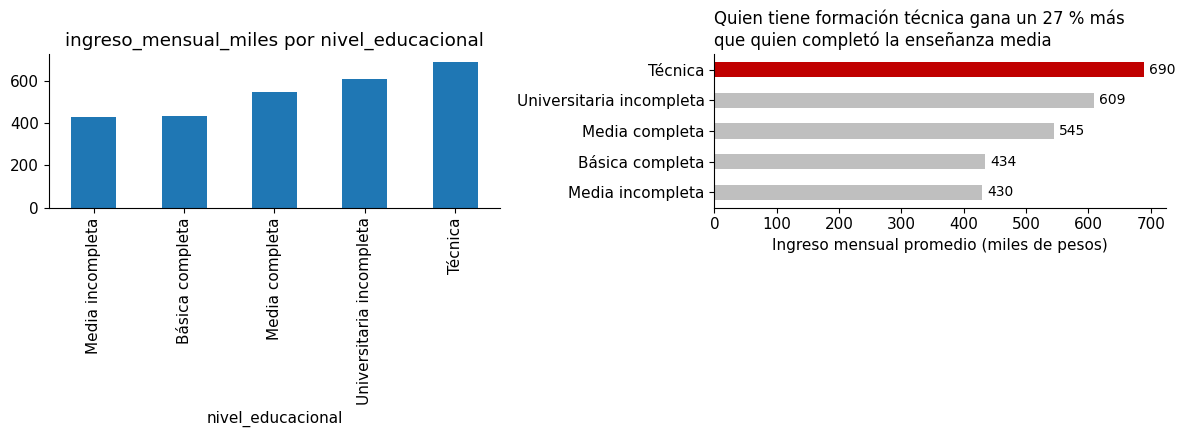

Verificación del titular: 26.6%


In [3]:
ingreso = p.groupby('nivel_educacional')['ingreso_mensual_miles'].mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# --- EXPLORATORIO: rápido, sin adornos, para mirarlo tú
ingreso.plot.bar(ax=ax[0])
ax[0].set_title('ingreso_mensual_miles por nivel_educacional')

# --- EXPLICATIVO: una idea, destacada
colores = ['#BFBFBF'] * len(ingreso)
colores[-1] = '#C00000'
ingreso.plot.barh(ax=ax[1], color=colores)
ax[1].set_title('Quien tiene formación técnica gana un 27 % más\nque quien completó la enseñanza media', loc='left', fontsize=12)
ax[1].set_xlabel('Ingreso mensual promedio (miles de pesos)')
ax[1].set_ylabel('')
for i, v in enumerate(ingreso):
    ax[1].text(v + 8, i, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=10)
plt.tight_layout(); plt.show()

print(f"Verificación del titular: {ingreso['Técnica']/ingreso['Media completa']-1:.1%}")

Cuatro cambios convierten uno en otro, y ninguno es decorativo:

1. **Barras horizontales**: las etiquetas largas se leen sin girar la cabeza.
2. **Gris salvo lo que importa**: el color dirige la mirada. Si todo es de colores, nada destaca.
3. **El valor sobre la barra**: quien quiera el número exacto no tiene que estimarlo contra el eje.
4. **Título que enuncia el hallazgo**, con la cifra verificada en la celda.

> **Verifica siempre el número que pones en el título.** Es el error más embarazoso posible: un titular que el propio gráfico desmiente.

### 1.2 Elegir el gráfico según la pregunta

| Si la pregunta es… | El gráfico es… | Evita |
|---|---|---|
| ¿Cuánto hay de cada categoría? | Barras (horizontales si son muchas o largas) | Torta con más de 4 porciones |
| ¿Cómo cambió en el tiempo? | Línea | Barras, que sugieren categorías independientes |
| ¿Cómo se distribuye una variable? | Histograma o caja | Solo el promedio |
| ¿Se relacionan dos variables? | Dispersión | Dos líneas con ejes distintos |
| ¿Cómo se compone un total? | Barras apiladas | Torta anidada, ilegible |

### ✏️ Actividad 1.1

Toma **dos hallazgos** de tu conjunto (semanas 3 y 4) y construye su versión explicativa. Para cada uno: elige el tipo según la pregunta, deja en gris lo secundario, rotula los valores y escribe un título que enuncie el hallazgo con su cifra.

Estos dos gráficos van al informe final.

In [4]:
mio = pd.read_csv(RUTA + 'S4_Online_Retail_Minado.csv', sep=';')
print(mio.shape)

# Actividad 1.1 — Gráfico explicativo 1
# Comparación de los grupos comerciales de Online Retail

# Trabajar con un registro por producto
productos = (
    mio.dropna(subset=['grupo'])
       .groupby(['StockCode', 'grupo'], as_index=False)
       .agg(importe_total=('ImporteLinea', 'sum'))
)

# Calcular el importe promedio acumulado de cada grupo
resumen = (
    productos.groupby('grupo')
             .agg(
                 productos=('StockCode', 'nunique'),
                 importe_promedio=('importe_total', 'mean')
             )
             .sort_index()
)

display(resumen.round(2))

(541909, 20)


,productos,importe_promedio
grupo,,
0.0,1380,464.55
1.0,1784,5124.28


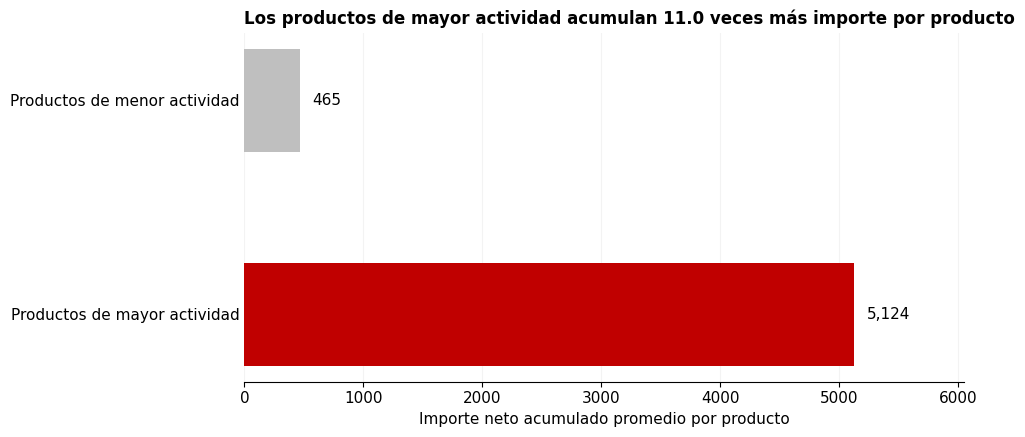

Relación verificada: 11.03 veces
Gráfico 1 exportado correctamente.


In [5]:
# Actividad 1.1 — Primer gráfico explicativo
# Importes medios acumulados por segmento comercial

valores = resumen['importe_promedio']
razon = valores.loc[1.0] / valores.loc[0.0]

etiquetas = [
    'Productos de menor actividad',
    'Productos de mayor actividad'
]

fig, ax = plt.subplots(figsize=(10, 4.5))

barras = ax.barh(
    etiquetas,
    [valores.loc[0.0], valores.loc[1.0]],
    color=['#BFBFBF', '#C00000'],
    height=0.48
)

for barra in barras:
    valor = barra.get_width()
    ax.text(
        valor + 110,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:,.0f}',
        va='center',
        fontsize=11
    )

ax.invert_yaxis()
ax.set_xlim(0, max(valores) * 1.18)
ax.set_xlabel('Importe neto acumulado promedio por producto')
ax.set_title(
    f'Los productos de mayor actividad acumulan {razon:.1f} veces '
    'más importe por producto',
    loc='left',
    fontsize=12,
    fontweight='bold'
)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('S5_Grafico1_Segmentos_Online_Retail.png',
            dpi=200, bbox_inches='tight')
plt.show()

print(f'Relación verificada: {razon:.2f} veces')
print('Gráfico 1 exportado correctamente.')

**Interpretación — Gráfico 1: Diferencias de actividad comercial entre segmentos**

El gráfico compara el importe neto acumulado promedio por producto de los dos segmentos identificados mediante K-Means en el conjunto Online Retail.

El grupo de menor actividad comercial contiene 1.380 productos, con un importe promedio acumulado de 464,55 por producto. En contraste, el grupo de mayor actividad contiene 1.784 productos, con un importe promedio de 5.124,28.

La relación calculada es de 11,03 veces, lo que muestra una diferencia considerable en la actividad comercial acumulada entre ambos segmentos.

Se utilizó un gráfico de barras horizontales con escala desde cero, etiquetas numéricas y un color destacado para facilitar la comparación. El título comunica directamente el principal hallazgo.

**Conclusión:** La segmentación identifica productos con niveles de actividad comercial muy diferentes. Sin embargo, esta comparación describe los grupos obtenidos mediante las propias variables comerciales utilizadas en K-Means, por lo que no constituye una validación independiente de la segmentación. Los importes incluyen cancelaciones y devoluciones, y no deben interpretarse directamente como ingresos contables definitivos.

In [6]:
# Actividad 1.1 — Preparación del segundo gráfico
# Productos con mayor importe neto acumulado

ranking_productos = (
    mio.groupby('StockCode', as_index=False)
       .agg(
           importe_neto=('ImporteLinea', 'sum'),
           lineas=('StockCode', 'size')
       )
       .sort_values('importe_neto', ascending=False)
)

# Mostrar los diez productos principales
display(ranking_productos.head(10).round(2))

,StockCode,importe_neto,lineas
4059,DOT,206245.48,710
1348,22423,164762.19,2203
2733,47566,98302.98,1727
3536,85123A,97894.50,2313
3515,85099B,92356.03,2159
1982,23084,66756.59,1067
4062,POST,66230.64,1256
1043,22086,63791.94,1210
3305,84879,58959.73,1502
2924,79321,53768.06,683


In [7]:
# Actividad 1.1 — Ranking de productos comerciales
# Utilizar los mismos productos seleccionados en Semana 4

codigos_comerciales = productos['StockCode'].unique()

ranking_comercial = (
    mio[mio['StockCode'].isin(codigos_comerciales)]
    .groupby('StockCode', as_index=False)
    .agg(
        importe_neto=('ImporteLinea', 'sum'),
        lineas=('StockCode', 'size')
    )
    .sort_values('importe_neto', ascending=False)
)

print('Productos comerciales:', len(ranking_comercial))
print('\nDiez productos con mayor importe neto acumulado:')
display(ranking_comercial.head(10).round(2))

Productos comerciales: 3164

Diez productos con mayor importe neto acumulado:


,StockCode,importe_neto,lineas
1172,22423,164762.19,2203
2375,47566,98302.98,1727
2892,85123A,97894.50,2313
2876,85099B,92356.03,2159
1790,23084,66756.59,1067
3162,POST,66230.64,1256
880,22086,63791.94,1210
2726,84879,58959.73,1502
2498,79321,53768.06,683
1246,22502,51041.37,484


In [8]:
# Actividad 1.1 — Ranking comercial para visualización
# Excluir códigos administrativos y gastos de envío

codigos_no_productos = [
    'DOT', 'POST', 'AMAZONFEE',
    'M', 'CRUK', 'BANK CHARGES', 'D'
]

ranking_grafico = (
    ranking_comercial[
        ~ranking_comercial['StockCode'].isin(codigos_no_productos)
    ]
    .copy()
)

print('Productos considerados para el gráfico:',
      len(ranking_grafico))

print('\nCinco productos con mayor importe neto:')
display(ranking_grafico.head(5).round(2))

Productos considerados para el gráfico: 3163

Cinco productos con mayor importe neto:


,StockCode,importe_neto,lineas
1172,22423,164762.19,2203
2375,47566,98302.98,1727
2892,85123A,97894.50,2313
2876,85099B,92356.03,2159
1790,23084,66756.59,1067


Diferencia entre los dos primeros: 67.6%


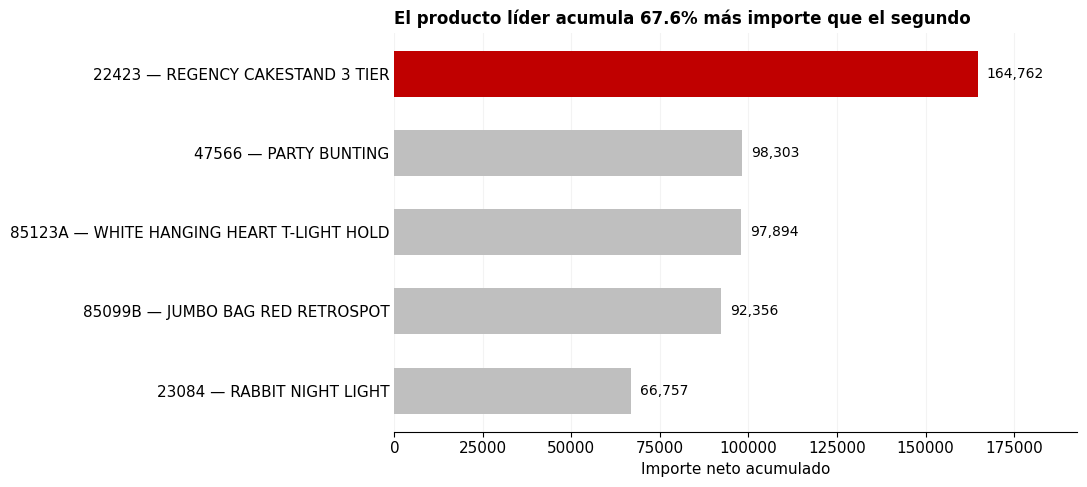

Gráfico 2 exportado correctamente.


In [9]:
# Actividad 1.1 — Segundo gráfico explicativo
# Cinco productos con mayor importe neto acumulado

top5 = ranking_grafico.head(5).copy()

# Recuperar la descripción más frecuente de cada producto
descripciones = (
    mio[mio['StockCode'].isin(top5['StockCode'])]
    .dropna(subset=['Description'])
    .groupby('StockCode')['Description']
    .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else '')
)

top5['descripcion'] = (
    top5['StockCode'].map(descripciones)
    .fillna('Sin descripción')
)

# Etiqueta: código y descripción abreviada
top5['etiqueta'] = (
    top5['StockCode'].astype(str) + ' — ' +
    top5['descripcion'].str.slice(0, 32)
)

# Verificar la diferencia entre los dos primeros
primero = top5.iloc[0]['importe_neto']
segundo = top5.iloc[1]['importe_neto']
diferencia_pct = (primero / segundo - 1) * 100

print('Diferencia entre los dos primeros:',
      f'{diferencia_pct:.1f}%')

# Ordenar de menor a mayor para barras horizontales
grafico = top5.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 5))

colores = [
    '#C00000' if codigo == top5.iloc[0]['StockCode']
    else '#BFBFBF'
    for codigo in grafico['StockCode']
]

barras = ax.barh(
    grafico['etiqueta'],
    grafico['importe_neto'],
    color=colores,
    height=0.58
)

for barra in barras:
    valor = barra.get_width()
    ax.text(
        valor + 2500,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:,.0f}',
        va='center',
        fontsize=10
    )

ax.set_xlim(0, primero * 1.17)
ax.set_xlabel('Importe neto acumulado')
ax.set_title(
    f'El producto líder acumula {diferencia_pct:.1f}% más '
    'importe que el segundo',
    loc='left',
    fontsize=12,
    fontweight='bold'
)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('S5_Grafico2_Top_Productos_Online_Retail.png',
            dpi=200, bbox_inches='tight')
plt.show()

print('Gráfico 2 exportado correctamente.')

**Interpretación — Gráfico 2: Productos con mayor importe neto acumulado**

El gráfico presenta los cinco productos comerciales con mayor importe neto acumulado en el conjunto Online Retail, excluyendo los códigos administrativos y los gastos de envío identificados durante la preparación del análisis.

El producto **22423 — REGENCY CAKESTAND 3 TIER** ocupa el primer lugar, con un importe neto acumulado de 164.762,19. Le sigue **47566 - PARTY BUNTING**, con 98.302,98.

La diferencia entre ambos productos es del **67,6 %**, lo que evidencia una ventaja considerable del producto líder respecto del segundo.

Los siguientes productos presentan importes acumulados de 97.894,50, 92.356,03 y 66.756,59, respectivamente.

Para comunicar este hallazgo se utilizó un gráfico de barras horizontales con escala desde cero, etiquetas numéricas y un color destacado para el producto líder. El título presenta una conclusión respaldada por los cálculos realizados.

**Conclusión:** El análisis permite identificar productos relevantes por su importe comercial acumulado, lo que puede orientar investigaciones posteriores sobre ventas, demanda e inventario. Sin embargo, los valores incluyen el efecto de cancelaciones y devoluciones, no representan utilidades y no permiten establecer por sí solos la rentabilidad de cada producto.

---
## Parte 2 · Representación honesta

Los dos gráficos de `S5_Graficos_Prensa_CDD.pdf` no contienen ningún dato falso. Vamos a reproducir sus distorsiones para entender exactamente qué hacen.

### 2.1 El eje truncado

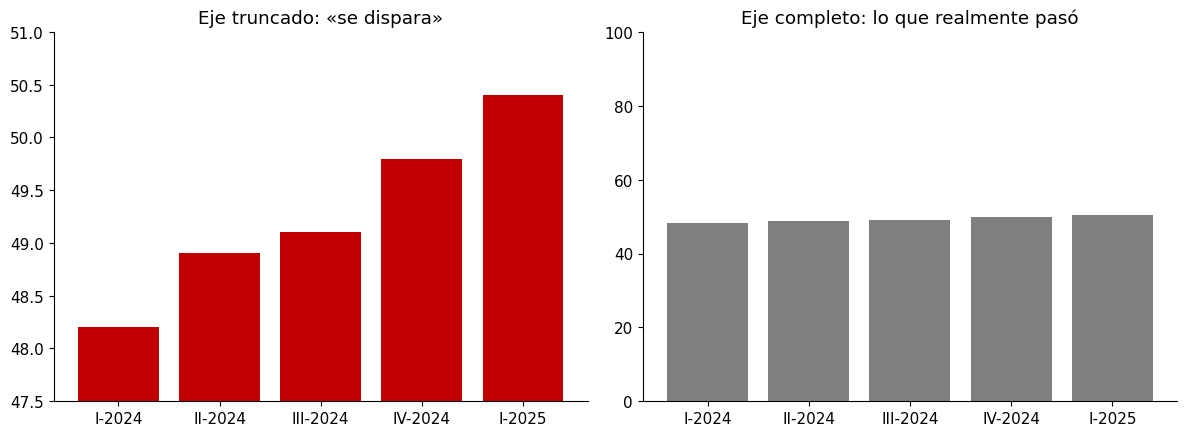

Variación real: 2.2 puntos = 4.6 %


In [10]:
trimestres = ['I-2024', 'II-2024', 'III-2024', 'IV-2024', 'I-2025']
satisfaccion = [48.2, 48.9, 49.1, 49.8, 50.4]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(trimestres, satisfaccion, color='#C00000')
ax[0].set_ylim(47.5, 51)
ax[0].set_title('Eje truncado: «se dispara»')

ax[1].bar(trimestres, satisfaccion, color='#7F7F7F')
ax[1].set_ylim(0, 100)
ax[1].set_title('Eje completo: lo que realmente pasó')
plt.tight_layout(); plt.show()

print(f'Variación real: {satisfaccion[-1] - satisfaccion[0]:.1f} puntos = '
      f'{(satisfaccion[-1]/satisfaccion[0] - 1)*100:.1f} %')

El mismo dato. A la izquierda parece una explosión; a la derecha, una línea casi plana. El aumento real es de **2,2 puntos, un 4,6 %**.

> **¿Truncar el eje es siempre deshonesto?** No. En una serie que oscila entre 48 y 51 nunca, mostrar desde cero puede ocultar variación relevante. La regla practicable es: **en gráficos de barras, el eje parte en cero** —porque la barra comunica magnitud por su largo—; **en gráficos de línea puedes truncar**, siempre que lo señales de forma visible.

### 2.2 Magnitudes brutas entre unidades de distinto tamaño

Esta es la misma trampa de la semana 3, ahora en formato gráfico.

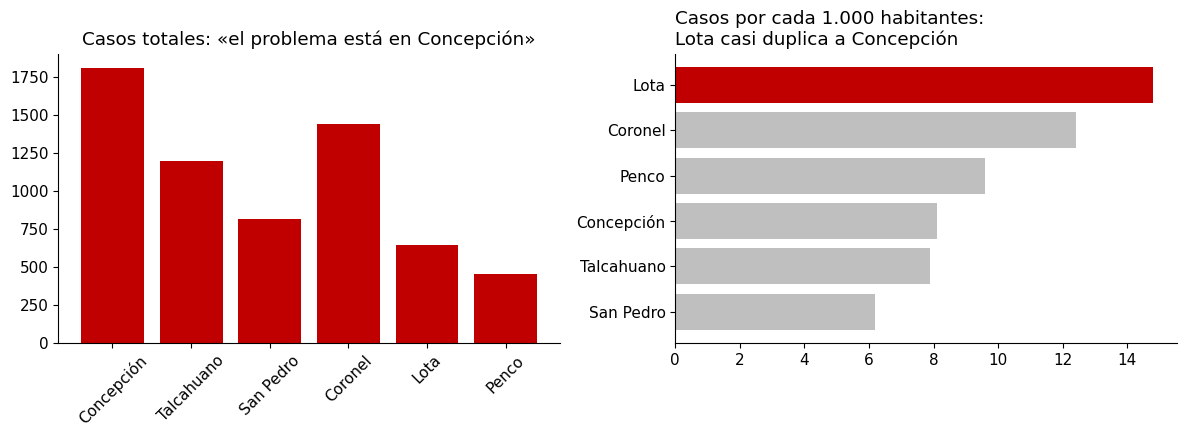

Lota             644 casos ·  14.8 por mil habitantes
Coronel         1441 casos ·  12.4 por mil habitantes
Penco            452 casos ·   9.6 por mil habitantes
Concepción      1810 casos ·   8.1 por mil habitantes
Talcahuano      1198 casos ·   7.9 por mil habitantes
San Pedro        817 casos ·   6.2 por mil habitantes


In [11]:
comunas = ['Concepción', 'Talcahuano', 'San Pedro', 'Coronel', 'Lota', 'Penco']
poblacion = [223574, 151749, 131808, 116262, 43535, 47105]
tasa = [8.1, 7.9, 6.2, 12.4, 14.8, 9.6]          # por cada 1.000 habitantes
casos = [int(pob * t / 1000) for pob, t in zip(poblacion, tasa)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(comunas, casos, color='#C00000')
ax[0].set_title('Casos totales: «el problema está en Concepción»')
ax[0].tick_params(axis='x', rotation=45)

orden = np.argsort(tasa)
col = ['#BFBFBF'] * 6
col[list(orden).index(4)] = '#C00000'
ax[1].barh([comunas[i] for i in orden], [tasa[i] for i in orden],
           color=[col[i] for i in range(6)])
ax[1].set_title('Casos por cada 1.000 habitantes:\nLota casi duplica a Concepción', loc='left')
plt.tight_layout(); plt.show()

for c, t, k in sorted(zip(comunas, tasa, casos), key=lambda x: -x[1]):
    print(f'{c:14s} {k:5d} casos · {t:5.1f} por mil habitantes')

A la izquierda, Concepción encabeza. A la derecha, **Concepción es de las más bajas** y Lota casi la duplica. Los datos son los mismos.

> **Regla:** si las unidades que comparas tienen tamaños distintos, normaliza antes de graficar. Casos por mil habitantes, ventas por metro cuadrado, accidentes por kilómetro recorrido.

### ✏️ Actividad 2.1

Revisa tus dos gráficos de la actividad 1.1 y responde:

- ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?
- ¿Comparas unidades de distinto tamaño sin normalizar?
- ¿El título afirma algo que el gráfico no muestra?
- ¿Omites algún período o categoría que cambiaría la lectura?

_Tu autorrevisión:_



**Actividad 2.1 — Autorrevisión de los gráficos de Online Retail**

**1. ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?**

No. Ambos gráficos utilizan barras horizontales y sus ejes numéricos comienzan en cero. Esto permite que la longitud de las barras represente proporcionalmente los importes, evitando exagerar visualmente las diferencias.

**2. ¿Comparamos unidades de distinto tamaño sin normalizar?**

En el primer gráfico se comparan dos grupos de diferente tamaño: 1.380 y 1.784 productos. Para evitar que el grupo con más productos presente un importe mayor simplemente por contener más integrantes, se utiliza el importe neto acumulado promedio por producto, en lugar de comparar los importes totales de cada grupo.

En el segundo gráfico se comparan importes netos acumulados por producto. La comparación es adecuada para identificar qué productos concentran mayores importes registrados, pero no permite concluir cuáles tienen mayor rentabilidad ni comparar su rendimiento por unidad vendida. Para ello se necesitarían métricas adicionales.

**3. ¿El título afirma algo que el gráfico no muestra?**

No. En el primer gráfico se afirma que el segmento de mayor actividad presenta 11,0 veces más importe acumulado promedio por producto, cifra comprobada mediante el cálculo de una relación de 11,03.

En el segundo gráfico se indica que el producto líder acumula un 67,6 % más importe que el segundo, cifra también verificada mediante código.

En ambos casos los títulos expresan hallazgos respaldados por los valores representados.

**4. ¿Se omite algún período o categoría que podría cambiar la interpretación?**

Sí, existen limitaciones que deben declararse. Los gráficos utilizan el período disponible en el conjunto Online Retail y no muestran su evolución temporal. Por lo tanto, no permiten concluir si estas diferencias se mantienen en todos los meses.

Además, el primer gráfico representa únicamente los productos que cumplieron los criterios de segmentación de la Semana 4. El segundo excluye códigos administrativos y gastos de envío, por lo que su clasificación corresponde a los productos comerciales seleccionados.

Los importes incluyen el efecto de cancelaciones y devoluciones, y no deben interpretarse como utilidades ni como ingresos contables auditados.

**Conclusión general**

Los dos gráficos utilizan escalas adecuadas, títulos verificados y comparaciones coherentes con sus objetivos. Sin embargo, sus limitaciones de selección, período y naturaleza de los importes deben acompañarlos en el informe final para evitar interpretaciones excesivas.

---
## Parte 3 · Anonimización

Trabajamos sobre `S5_Dataset_Personales_Sintetico_CDD.csv`: 420 participantes de un programa municipal de capacitación.

⚠️ **Los datos son sintéticos**: nombres, RUT y direcciones fueron generados artificialmente para este curso. Los RUT usan un rango no asignado a personas naturales. **No corresponden a nadie real.**

In [12]:
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p.head(3)

Forma: (420, 15)


,participante_id,nombre_completo,rut,email,fecha_nacimiento,sexo,comuna,direccion,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,Florencia Pérez Araya,93.939.245-8,florencia.pérez73@correo.cl,1968-07-09,M,Coronel,Prat 786,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,Florencia Silva Valenzuela,91.854.251-6,florencia.silva25@correo.cl,1978-01-21,M,Lota,Maipú 3523,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,Paula Fuentes Torres,94.822.480-K,paula.fuentes59@correo.cl,1998-03-13,F,Concepción,Barros Arana 1620,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


### 3.1 Los tres tipos de identificador

| Tipo | Qué es | En este conjunto |
|---|---|---|
| **Identificador directo** | Identifica por sí solo | nombre_completo, rut, email, direccion |
| **Cuasi-identificador** | No identifica solo, pero sí **en combinación** | comuna, sexo, fecha_nacimiento, ocupacion |
| **Atributo sensible** | Lo que no queremos revelar de nadie | ingreso_mensual_miles, situacion_laboral |

El error clásico es creer que basta con borrar la primera fila de la tabla. Vamos a comprobar que no.

### 3.2 Paso 1 · Quitar los identificadores directos

In [13]:
DIRECTOS = ['nombre_completo', 'rut', 'email', 'direccion']
anon = p.drop(columns=DIRECTOS).copy()
print('Columnas restantes:', list(anon.columns))
anon.head(3)

Columnas restantes: ['participante_id', 'fecha_nacimiento', 'sexo', 'comuna', 'ocupacion', 'nivel_educacional', 'situacion_laboral', 'ingreso_mensual_miles', 'programa', 'asistencia_pct', 'aprobado']


,participante_id,fecha_nacimiento,sexo,comuna,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,1968-07-09,M,Coronel,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,1978-01-21,M,Lota,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,1998-03-13,F,Concepción,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


Sin nombre, sin RUT, sin correo y sin dirección. **¿Está anonimizado?**

### 3.3 Paso 2 · Medir el k-anonimato

El **k-anonimato** mide cuántas personas comparten exactamente la misma combinación de cuasi-identificadores. Si k = 1, esa persona es **única en el conjunto**: quien conozca esos cuatro datos suyos la encuentra sin más.

In [14]:
QI = ['comuna', 'sexo', 'fecha_nacimiento', 'ocupacion']
grupos = anon.groupby(QI).size()

print(f'Combinaciones distintas : {len(grupos)}')
print(f'Personas con k = 1      : {(grupos == 1).sum()}  '
      f'({(grupos == 1).sum()/len(anon)*100:.1f} % del conjunto)')
print(f'k mínimo                : {grupos.min()}')

Combinaciones distintas : 420
Personas con k = 1      : 420  (100.0 % del conjunto)
k mínimo                : 1


**420 de 420.** Todas las personas son únicas. El conjunto no está anonimizado en absoluto: cualquiera que sepa la comuna, el sexo, la fecha de nacimiento y el oficio de un conocido puede encontrar su ingreso y su situación laboral.

> Esto no es una hipótesis de laboratorio. En 2006 Netflix publicó un conjunto «anonimizado» de calificaciones de películas; investigadores reidentificaron usuarios cruzándolo con IMDb. En 2014, los registros de taxis de Nueva York permitieron rastrear viajes individuales.

### 3.4 Paso 3 · Generalizar

In [15]:
anon['anio_nacimiento'] = pd.to_datetime(anon['fecha_nacimiento']).dt.year
anon['tramo_edad'] = ((2026 - anon['anio_nacimiento']) // 10 * 10).astype(str) + '-' + \
                     (((2026 - anon['anio_nacimiento']) // 10 * 10) + 9).astype(str)
anon = anon.drop(columns=['fecha_nacimiento', 'anio_nacimiento', 'ocupacion'])

g2 = anon.groupby(['comuna', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g2)}')
print(f'Personas k = 1: {(g2 == 1).sum()}')
print(f'k mínimo      : {g2.min()}')

Combinaciones : 97
Personas k = 1: 5
k mínimo      : 1


De 420 únicos bajamos a 5. Mejor, pero **cinco personas siguen siendo identificables**.

### 3.5 Paso 4 · Generalizar un nivel más

In [16]:
# Las diez comunas pertenecen a la Provincia de Concepción
anon['provincia'] = 'Concepción'
g3 = anon.groupby(['provincia', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g3)}')
print(f'Personas k = 1: {(g3 == 1).sum()}')
print(f'k mínimo      : {g3.min()}')
print('\nTamaño de cada grupo:')
print(g3.sort_values().to_string())

Combinaciones : 10
Personas k = 1: 0
k mínimo      : 23

Tamaño de cada grupo:
provincia   sexo  tramo_edad
Concepción  M     20-29         23
            F     20-29         35
            M     50-59         37
            F     40-49         38
                  60-69         40
                  30-39         43
            M     60-69         43
                  30-39         52
                  40-49         52
            F     50-59         57


Ahora **ninguna persona es única** y el grupo más pequeño tiene 23 integrantes. El conjunto cumple k-anonimato con k = 23.

> **El precio de la privacidad es resolución.** Perdimos la comuna y el oficio: ya no podemos comparar Lota con Concepción. Ese es el intercambio, y es una decisión que se declara en el informe, no un detalle técnico.

### ✏️ Actividad 3.1 — Seudonimización

A veces necesitas seguir a la misma persona entre dos archivos sin saber quién es. Para eso sirve el **seudónimo**: un código estable que reemplaza al identificador.

Escribe el código que genere un seudónimo para cada participante a partir de su RUT, usando una función de resumen (`hashlib.sha256`). Después responde: **¿por qué un seudónimo NO es lo mismo que una anonimización?**

In [17]:
import hashlib

# Actividad 3.1 — Seudonimización

def seudonimo(valor, sal='CDD-2026'):
    return hashlib.sha256(
        (sal + str(valor)).encode()
    ).hexdigest()[:12]

# Generar un seudónimo estable para cada participante
p['seudonimo'] = p['rut'].apply(seudonimo)

# Mostrar una muestra
p[['rut', 'seudonimo']].head()

,rut,seudonimo
0,93.939.245-8,e87d78b75a09
1,91.854.251-6,8bec038871af
2,94.822.480-K,5e7367c99892
3,90.640.340-6,0e0383cb030e
4,97.378.918-5,037c173c3e01


Un seudónimo no es lo mismo que una anonimización porque reemplazar un identificador directo por un código no elimina necesariamente la posibilidad de volver a relacionar el registro con una persona.

En este caso, el mismo RUT siempre produce el mismo seudónimo al utilizar la misma función y la misma sal. Esto permite seguir al mismo participante entre distintos archivos sin utilizar directamente su RUT.

Sin embargo, el registro continúa siendo vinculable y conserva otros atributos que pueden facilitar una reidentificación, como sexo, comuna, edad u otras características. Además, si se conoce el procedimiento utilizado para generar el seudónimo, podrían intentarse ataques de comparación sobre valores conocidos.

Por lo tanto, la seudonimización reduce la exposición de los identificadores directos, pero los datos siguen siendo personales y requieren medidas de protección. La anonimización, en cambio, busca impedir razonablemente la reidentificación de las personas.


---
## Parte 4 · Detección de sesgo

Un conjunto de datos puede estar limpio, ser representativo de lo que registra, y **aun así** llevar a decisiones injustas. El sesgo no está en los cálculos: está en qué se registró y a quién.

### 4.1 ¿Quién está en el conjunto?

In [18]:
print('Composición del programa:\n')
for col in ['sexo', 'nivel_educacional', 'situacion_laboral']:
    print(col.upper())
    print(p[col].value_counts(normalize=True).round(3).to_string())
    print()

Composición del programa:

SEXO
sexo
F    0.507
M    0.493

NIVEL_EDUCACIONAL
nivel_educacional
Media completa              0.414
Técnica                     0.207
Media incompleta            0.160
Universitaria incompleta    0.110
Básica completa             0.110

SITUACION_LABORAL
situacion_laboral
Ocupado       0.612
Desocupado    0.276
Inactivo      0.112



### 4.2 ¿A quién no describe?

Esta es la pregunta que casi nadie hace, y la que más consecuencias tiene.

Este conjunto contiene a quienes **se inscribieron y participaron** en el programa. No contiene a quienes no se enteraron, a quienes no pudieron asistir por horario o transporte, ni a quienes abandonaron antes del registro.

> Si con estos datos concluyes «el programa funciona, el 57 % aprueba», estás describiendo a los participantes, no a la población objetivo. Es exactamente el error de las encuestas de satisfacción respondidas solo por quienes quisieron responder.

In [19]:
# Comprobación: ¿el resultado depende de algún grupo?
tabla = p.groupby('nivel_educacional').agg(
    n=('aprobado', 'size'),
    tasa_aprobacion=('aprobado', lambda s: (s == 'Sí').mean()),
    asistencia_media=('asistencia_pct', 'mean'),
).round(3).sort_values('tasa_aprobacion')
tabla

,n,tasa_aprobacion,asistencia_media
nivel_educacional,,,
Básica completa,46,0.500,77.348
Técnica,87,0.540,76.161
Universitaria incompleta,46,0.587,74.717
Media completa,174,0.609,77.103
Media incompleta,67,0.642,78.328


### ✏️ Actividad 4.1 — El sesgo de tu conjunto

Responde sobre **tu propio conjunto de datos**, en la celda siguiente. Estas tres respuestas van íntegras a la sección de limitaciones de tu informe final:

1. **¿Quién queda fuera?** ¿Qué personas, casos o situaciones no están registrados y por qué?
2. **¿El modo de recolección favorece a algún grupo?** ¿Quién tuvo más probabilidad de quedar registrado?
3. **¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?** Escríbela textualmente: es la advertencia que debes incluir en el informe.

**1. Quién queda fuera:**

El conjunto Online Retail contiene únicamente las operaciones que fueron efectivamente registradas en el sistema durante el período analizado.

Por lo tanto, quedan fuera las personas que conocieron o visitaron la tienda pero no realizaron una compra, los clientes que abandonaron el proceso antes de concretar una transacción y cualquier operación que no haya quedado registrada en este sistema.

Además, algunos registros no cuentan con CustomerID, por lo que no es posible identificar de manera consistente a todos los clientes participantes.

En consecuencia, el conjunto describe principalmente las transacciones registradas y no representa a todas las personas potencialmente interesadas en los productos ni a todo el mercado.

**2. ¿El modo de recolección favorece a algún grupo?**

Sí. El conjunto favorece a quienes efectivamente realizaron transacciones registradas por la empresa, por lo que los clientes más activos tienen mayor probabilidad de aparecer repetidas veces en los datos.

También existe una fuerte presencia de operaciones provenientes del Reino Unido, por lo que los patrones observados pueden reflejar principalmente el comportamiento de ese mercado y no necesariamente el de otros países representados en menor proporción.

Además, los productos de mayor rotación generan muchas más líneas de transacción que los productos vendidos con menor frecuencia. Esto hace que los análisis puedan estar más influenciados por los clientes y productos con mayor actividad registrada.

Por lo tanto, la forma en que se recopilaron los datos no representa de manera uniforme a todos los clientes, productos o mercados posibles.


**3. Conclusión equivocada que hay que prevenir:**

Una conclusión equivocada sería afirmar que los patrones encontrados representan el comportamiento de todos los consumidores o de todo el mercado minorista.

El conjunto Online Retail describe únicamente las transacciones efectivamente registradas en el sistema durante el período disponible. Por lo tanto, sus resultados están condicionados por quiénes compraron, qué productos se vendieron, qué países están más representados y qué operaciones quedaron registradas.

Tampoco debe concluirse que los productos con mayor importe acumulado sean necesariamente los más rentables, ni que los segmentos identificados mediante K-Means correspondan a categorías universales de productos.

**Los hallazgos de este análisis describen el comportamiento del conjunto de transacciones registradas y deben interpretarse como resultados exploratorios condicionados por la cobertura y composición de los datos, no como conclusiones generales sobre todos los consumidores o el mercado completo.**

---
## Parte 5 · Cerrar la ficha ético-legal

Abre `S1_Ficha_Riesgo_Etico_CDD.docx`, la que completaste en la semana 1, y ciérrala con lo que ahora sabes:

- **Punto 4 (riesgos y resguardos):** qué resguardos aplicaste efectivamente durante la preparación y el análisis, no los que pensabas aplicar.
- **Punto 5 (sesgo):** las tres respuestas de la actividad 4.1.
- **Punto 6 (declaración de uso):** fírmala.

Esa ficha cerrada **es la Sección C de la Entrega Final**, junto con tu plan de actualización.

---
## Cierre y versionado

In [20]:
# Guarda las figuras del informe en archivos, para insertarlas en el documento
# fig.savefig('figura_1.png', dpi=200, bbox_inches='tight')
print('Recuerda exportar tus dos gráficos explicativos a .png con dpi=200')

Recuerda exportar tus dos gráficos explicativos a .png con dpi=200


In [21]:
# En una terminal:
# git add S5_Notebook_Laboratorio_CDD.ipynb figura_*.png
# git commit -m 'Semana 5: visualizaciones explicativas, anonimizacion y sesgo'
# git push


**Enlace a mi repositorio:**
https://github.com/fariasad/UCSC-Ciencia-de-Datos

---

## Antes de cerrar el laboratorio

- [x] Dos gráficos explicativos, con título que enuncia el hallazgo y cifra verificada
- [x] Autorrevisión de honestidad: ejes, normalización, títulos, omisiones
- [x] Recorrido de anonimización completo, con el k-anonimato medido en cada paso
- [x] Seudonimización implementada y explicada
- [x] Las tres respuestas sobre el sesgo de mi conjunto
- [x] Ficha ético-legal cerrada y firmada
- [x] Figuras exportadas a .png para el informe

_Ciencia de Datos · Advance UCSC · Semana 5_